# Real-Time Data Quality & Anomaly Detection – Delivery Logistics

This notebook validates Technical Data Quality (TDQ) and Business Data Quality (BDQ).

It builds a predictive anomaly detection model for delivery logistics data.

It simulates a real-time data gatekeeper for 100+ tables, using `delivery_logistics.csv` as a representative dataset.


In [38]:
# Setup: Install required packages if not already installed
# This cell ensures all dependencies are available in the current Python environment

import subprocess
import sys

def install_if_missing(package_name, import_name=None):
    """Install a package if it's not importable."""
    if import_name is None:
        import_name = package_name

    try:
        __import__(import_name)
        print(f"✅ {package_name} is already installed")
    except ImportError:
        print(f"⚠️  {package_name} not found. Installing...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", package_name])
        print(f"✅ {package_name} installed successfully")

# Install core dependencies
install_if_missing("pyspark")
install_if_missing("pandas")
install_if_missing("matplotlib")
install_if_missing("plotly", "plotly.express")
install_if_missing("pyyaml", "yaml")
install_if_missing("python-dotenv", "dotenv")
# Install scikit-learn if needed (though we use PySpark's IsolationForest, not sklearn's)
install_if_missing("scikit-learn", "sklearn")

print("\n✅ All required packages are ready!")


✅ pyspark is already installed
✅ pandas is already installed
✅ matplotlib is already installed
✅ plotly is already installed
✅ pyyaml is already installed
✅ python-dotenv is already installed
✅ scikit-learn is already installed

✅ All required packages are ready!


In [39]:
# Fast Startup: Imports and Spark configuration (optimized for speed)

import time
from pyspark.sql import SparkSession
from pyspark.sql import functions as F, types as T
from pyspark.ml.feature import VectorAssembler, StandardScaler

# Note: IsolationForest will be imported conditionally below (PySpark's version, not sklearn's)

start_time = time.time()
print("=" * 80)
print("🚀 Starting Delivery Logistics Data Quality & Anomaly Detection Pipeline")
print("=" * 80)
print(f"⏰ Start time: {time.strftime('%Y-%m-%d %H:%M:%S')}\n")

# Minimal, fast import checks for external Python libs
def _try_import(module, alias=None):
    try:
        if alias:
            globals()[alias] = __import__(module)
        else:
            __import__(module)
        return True
    except Exception:
        return False

# Only print on first import attempt
print("📦 Importing PySpark ML libraries...")
HAS_ISOLATION_FOREST = _try_import("pyspark.ml.iforest", "IsolationForest")
if HAS_ISOLATION_FOREST:
    from pyspark.ml.iforest import IsolationForest
    print("✅ IsolationForest available")
else:
    IsolationForest = None
    print("⚠️  IsolationForest not available, will use z-score fallback")

import pandas as pd
import matplotlib.pyplot as plt

# Quick in-place check for plotly (don't print unnecessary info)
if _try_import("plotly.express", "px"):
    print("✅ Plotly available")
else:
    px = None
    print("⚠️  Plotly not available")

# Check Databricks utilities quickly (avoid slow errors)
if "dbutils" in globals():
    print("✅ Databricks utilities available")
else:
    dbutils = None
    print("ℹ️  Running in non-Databricks environment")

print("\n⚙️  Configuring Spark session for optimal performance...")

# Speed up Spark session launch for typical small laptop/testing workloads:
spark_start_time = time.time()
spark = (
    SparkSession.builder
    .appName("DeliveryLogisticsDQ_AnomalyDetection")
    # Key: 1 partition if tiny, else use all CPUs detected
    .config("spark.sql.shuffle.partitions", str(max(2, min(8, __import__('os').cpu_count() or 4))))
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.sql.adaptive.coalescePartitions.enabled", "true")
    .config("spark.serializer", "org.apache.spark.serializer.KryoSerializer")
    .config("spark.sql.execution.arrow.maxRecordsPerBatch", "16000")
    .config("spark.driver.memory", "3g")
    .config("spark.executor.memory", "3g")
    .getOrCreate()
)

# Best practices for timezone and shuffle
spark.conf.set("spark.sql.session.timeZone", "UTC")
spark.conf.set("spark.sql.adaptive.skewJoin.enabled", "true")

spark_elapsed = time.time() - spark_start_time

print(f"✅ Spark session created successfully")
print(f"   ⏱️  Spark session creation time: {spark_elapsed:.2f} seconds")
print(f"   Spark version: {spark.version}")
print(f"   Default parallelism: {spark.sparkContext.defaultParallelism}")
print(f"   Shuffle partitions: {spark.conf.get('spark.sql.shuffle.partitions')}\n")
elapsed = time.time() - start_time
print(f"⏱️  Total setup completed in {elapsed:.2f} seconds")
print("=" * 80)
print()


🚀 Starting Delivery Logistics Data Quality & Anomaly Detection Pipeline
⏰ Start time: 2025-12-04 19:35:53

📦 Importing PySpark ML libraries...
⚠️  IsolationForest not available, will use z-score fallback
✅ Plotly available
✅ Databricks utilities available

⚙️  Configuring Spark session for optimal performance...
✅ Spark session created successfully
   ⏱️  Spark session creation time: 0.01 seconds
   Spark version: 3.5.1
   Default parallelism: 2
   Shuffle partitions: 2

⏱️  Total setup completed in 0.01 seconds



In [40]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [41]:
# Load raw delivery logistics dataset

import time
step_start = time.time()

print("=" * 80)
print("📂 STEP 1: Loading raw dataset")
print("=" * 80)

# Adjust the path as needed if running from DBFS or another storage location
# Example for DBFS:
# df_raw = spark.read.option("header", "true").option("inferSchema", "true").csv("/mnt/data/delivery_logistics.csv")

csv_path = "Delivery_Logistics.csv"
print(f"📁 Reading CSV from: {csv_path}")

df_raw = (
    spark.read
        .option("header", "true")
        .option("inferSchema", "true")
        .option("inferTimestamp", "true")  # Faster timestamp inference
        .csv(csv_path)
)

print("⏳ Counting rows and caching DataFrame...")
# Cache the DataFrame for repeated access
df_raw.cache()
row_count = df_raw.count()  # materialize cache

print(f"✅ Dataset loaded successfully!")
print(f"   📊 Total rows: {row_count:,}")
print(f"   📋 Total columns: {len(df_raw.columns)}")
print(f"   📝 Column names: {', '.join(df_raw.columns[:10])}{'...' if len(df_raw.columns) > 10 else ''}")

elapsed = time.time() - step_start
print(f"⏱️  Load time: {elapsed:.2f} seconds")
print("=" * 80)
print()



📂 STEP 1: Loading raw dataset
📁 Reading CSV from: Delivery_Logistics.csv
⏳ Counting rows and caching DataFrame...
✅ Dataset loaded successfully!
   📊 Total rows: 25,000
   📋 Total columns: 15
   📝 Column names: delivery_id, delivery_partner, package_type, vehicle_type, delivery_mode, region, weather_condition, distance_km, package_weight_kg, delivery_time_hours...
⏱️  Load time: 0.47 seconds



In [42]:
# Inspect schema and sample rows

print("Schema of df_raw:")
df_raw.printSchema()

print("\nSample rows:")
try:
    display(df_raw)  # Databricks environment
except NameError:
    df_raw.show(20, truncate=False)



Schema of df_raw:
root
 |-- delivery_id: double (nullable = true)
 |-- delivery_partner: string (nullable = true)
 |-- package_type: string (nullable = true)
 |-- vehicle_type: string (nullable = true)
 |-- delivery_mode: string (nullable = true)
 |-- region: string (nullable = true)
 |-- weather_condition: string (nullable = true)
 |-- distance_km: double (nullable = true)
 |-- package_weight_kg: double (nullable = true)
 |-- delivery_time_hours: timestamp (nullable = true)
 |-- expected_time_hours: timestamp (nullable = true)
 |-- delayed: string (nullable = true)
 |-- delivery_status: string (nullable = true)
 |-- delivery_rating: integer (nullable = true)
 |-- delivery_cost: double (nullable = true)


Sample rows:


DataFrame[delivery_id: double, delivery_partner: string, package_type: string, vehicle_type: string, delivery_mode: string, region: string, weather_condition: string, distance_km: double, package_weight_kg: double, delivery_time_hours: timestamp, expected_time_hours: timestamp, delayed: string, delivery_status: string, delivery_rating: int, delivery_cost: double]

### Dataset overview

The delivery logistics dataset is expected to contain one row per delivery event, with fields such as:

- **delivery_id**: Unique identifier for the delivery instance.
- **order_id**: Identifier of the customer order associated with the delivery.
- **route_id**: Identifier for the planned route or trip.
- **pickup_time / dropoff_time**: Timestamps capturing when the delivery is picked up and completed.
- **distance_km**: Estimated or actual distance traveled in kilometers.
- **duration_min**: Transit time in minutes between pickup and dropoff.
- **cost / price / fee**: Monetary metrics such as delivery cost, price charged, or fees.
- **status**: Operational status (e.g., pending, in_transit, completed, cancelled, failed).
- **city / region / country**: Geographic attributes for the delivery.
- **vehicle_type / courier_id**: Logistics resource attributes.

The **exact column names and availability** are taken directly from the `delivery_logistics.csv` file, and the subsequent logic in this notebook will **dynamically adapt** to the available schema and data types.


## Technical Data Quality (TDQ)

This section evaluates **Technical Data Quality** across the following pillars:

- **Schema compliance**: Do the columns and data types match the expected technical definition?
- **Completeness (null rates)**: How many missing values exist per column?
- **Uniqueness**: Are key identifiers unique, or do we have duplicates?
- **Timeliness (freshness)**: How up to date is the dataset relative to current time?


In [43]:
# TDQ: Schema compliance

# Define an "expected schema" at a logical/semantic level (not strict Spark types)
# Categories: numeric, timestamp, string
expected_schema = {
    "delivery_id": "numeric",
    "order_id": "numeric",
    "route_id": "numeric",
    "pickup_time": "timestamp",
    "dropoff_time": "timestamp",
    "event_time": "timestamp",
    "created_at": "timestamp",
    "distance_km": "numeric",
    "duration_min": "numeric",
    "cost": "numeric",
    "price": "numeric",
    "fee": "numeric",
    "status": "string",
    "city": "string",
    "region": "string",
    "country": "string",
    "vehicle_type": "string",
    "courier_id": "numeric",
}

# Helper to map concrete Spark data types to logical categories
def categorize_spark_type(dt):
    from pyspark.sql import types as T

    if isinstance(dt, (T.ByteType, T.ShortType, T.IntegerType, T.LongType, T.FloatType, T.DoubleType, T.DecimalType)):  # numeric
        return "numeric"
    if isinstance(dt, (T.TimestampType, T.DateType)):
        return "timestamp"
    # Default everything else to string/other
    if isinstance(dt, (T.StringType,)):
        return "string"
    return "other"

schema_rows = []
for field in df_raw.schema:
    col_name = field.name
    actual_type = str(field.dataType)
    actual_category = categorize_spark_type(field.dataType)
    expected_category = expected_schema.get(col_name, "(not_specified)")
    is_matching = (expected_category == actual_category) if expected_category != "(not_specified)" else None
    schema_rows.append({
        "column_name": col_name,
        "expected_type": expected_category,
        "actual_type": actual_type,
        "actual_category": actual_category,
        "is_matching": is_matching,
    })

schema_compliance_df = spark.createDataFrame(schema_rows)

print("Schema compliance (by column):")
try:
    display(schema_compliance_df.orderBy("column_name"))
except NameError:
    schema_compliance_df.orderBy("column_name").show(truncate=False)

print("\nColumns with mismatched or unspecified expected types:")
try:
    display(schema_compliance_df.filter(schema_compliance_df.is_matching == False))
except NameError:
    schema_compliance_df.filter(schema_compliance_df.is_matching == False).show(truncate=False)


Schema compliance (by column):


DataFrame[actual_category: string, actual_type: string, column_name: string, expected_type: string, is_matching: boolean]


Columns with mismatched or unspecified expected types:


DataFrame[actual_category: string, actual_type: string, column_name: string, expected_type: string, is_matching: boolean]

🔍 STEP 2: TDQ Completeness Check (Null Rates)
⏳ Computing null rates for all columns (optimized single-pass)...
✅ Computed null counts for 15 columns
   📊 Total rows: 25,000

📋 Null-rate summary by column:


DataFrame[column_name: string, null_count: bigint, null_rate: double, total_count: bigint]


📊 Generating visualization...


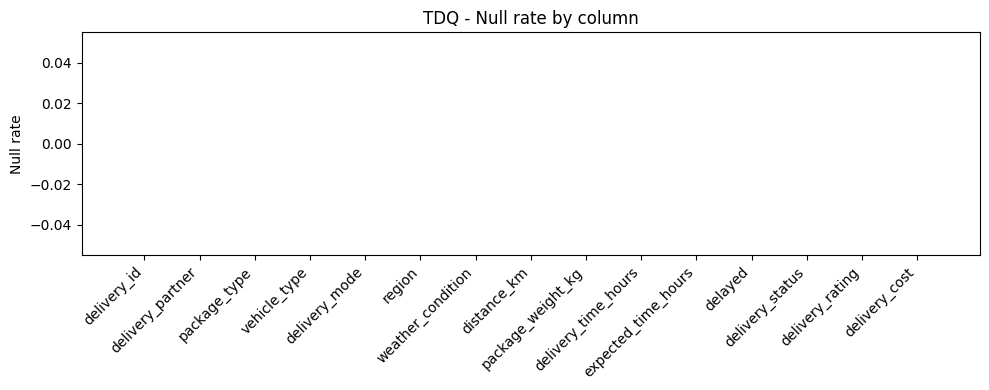


⏱️  TDQ Completeness check completed in 1.47 seconds



In [44]:
# TDQ: Completeness (null rates)

import time
step_start = time.time()

print("=" * 80)
print("🔍 STEP 2: TDQ Completeness Check (Null Rates)")
print("=" * 80)

from pyspark.sql import functions as F

# Optimized: Compute all null counts in a single aggregation instead of per-column filters
print("⏳ Computing null rates for all columns (optimized single-pass)...")

# Build aggregation expressions for all columns at once
agg_exprs = [F.count(F.lit(1)).alias("total_count")]
for c in df_raw.columns:
    agg_exprs.append(F.sum(F.when(F.col(c).isNull(), 1).otherwise(0)).alias(f"null_{c}"))

# Single aggregation pass
null_results = df_raw.agg(*agg_exprs).collect()[0]
total_count = null_results["total_count"]

print(f"✅ Computed null counts for {len(df_raw.columns)} columns")
print(f"   📊 Total rows: {total_count:,}")

# Build summary DataFrame
null_stats = []
for c in df_raw.columns:
    null_count = null_results[f"null_{c}"]
    null_rate = null_count / total_count if total_count > 0 else None
    null_stats.append({
        "column_name": c,
        "null_count": null_count,
        "total_count": total_count,
        "null_rate": null_rate,
    })

tdq_null_summary = spark.createDataFrame(null_stats)

print("\n📋 Null-rate summary by column:")
try:
    display(tdq_null_summary.orderBy(F.desc("null_rate")))
except NameError:
    tdq_null_summary.orderBy(F.desc("null_rate")).show(truncate=False)

# Plot null rates as a bar chart using pandas + matplotlib
print("\n📊 Generating visualization...")
null_pdf = tdq_null_summary.orderBy(F.desc("null_rate")).toPandas()

plt.figure(figsize=(10, 4))
plt.bar(null_pdf["column_name"], null_pdf["null_rate"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Null rate")
plt.title("TDQ - Null rate by column")
plt.tight_layout()
plt.show()

elapsed = time.time() - step_start
print(f"\n⏱️  TDQ Completeness check completed in {elapsed:.2f} seconds")
print("=" * 80)
print()



In [45]:
# TDQ: Uniqueness

from pyspark.sql import functions as F

# Choose a reasonable key based on available columns
primary_key = None
if "delivery_id" in df_raw.columns:
    primary_key = ["delivery_id"]
elif all(c in df_raw.columns for c in ["order_id", "route_id", "pickup_time"]):
    primary_key = ["order_id", "route_id", "pickup_time"]

if primary_key is None:
    print("No suitable key columns (e.g., delivery_id or (order_id, route_id, pickup_time)) were found for uniqueness checks.")
else:
    print(f"Using primary key columns for uniqueness check: {primary_key}")

    total_rows = df_raw.count()
    distinct_key_count = df_raw.select([F.col(c) for c in primary_key]).distinct().count()
    duplicate_count = total_rows - distinct_key_count

    print(f"Total rows: {total_rows}")
    print(f"Distinct key count: {distinct_key_count}")
    print(f"Duplicate key rows: {duplicate_count}")

    if duplicate_count > 0:
        print("\nSample duplicate key combinations:")
        dup_keys_df = (
            df_raw.groupBy([F.col(c) for c in primary_key])
                  .count()
                  .filter(F.col("count") > 1)
                  .orderBy(F.desc("count"))
                  .limit(20)
        )
        try:
            display(dup_keys_df)
        except NameError:
            dup_keys_df.show(truncate=False)

        print("\nSample duplicate rows:")
        dup_rows_df = df_raw.join(dup_keys_df.drop("count"), on=primary_key, how="inner").limit(20)
        try:
            display(dup_rows_df)
        except NameError:
            dup_rows_df.show(truncate=False)



Using primary key columns for uniqueness check: ['delivery_id']
Total rows: 25000
Distinct key count: 24502
Duplicate key rows: 498

Sample duplicate key combinations:


DataFrame[delivery_id: double, count: bigint]


Sample duplicate rows:


DataFrame[delivery_id: double, delivery_partner: string, package_type: string, vehicle_type: string, delivery_mode: string, region: string, weather_condition: string, distance_km: double, package_weight_kg: double, delivery_time_hours: timestamp, expected_time_hours: timestamp, delayed: string, delivery_status: string, delivery_rating: int, delivery_cost: double]

In [46]:
# TDQ: Timeliness (freshness)

from pyspark.sql import functions as F

# Identify a main timestamp column based on common logistics fields
candidate_ts_cols = [
    "event_time",
    "pickup_time",
    "created_at",
    "dropoff_time",
]

timestamp_col = None
for c in candidate_ts_cols:
    if c in df_raw.columns:
        timestamp_col = c
        break

# If none of the common names exist, fall back to the first TimestampType column, if any
if timestamp_col is None:
    ts_cols_in_schema = [f.name for f in df_raw.schema if isinstance(f.dataType, __import__("pyspark.sql.types", fromlist=["TimestampType"]).TimestampType)]
    if ts_cols_in_schema:
        timestamp_col = ts_cols_in_schema[0]

if timestamp_col is None:
    print("No timestamp column found for timeliness checks.")
else:
    print(f"Using timestamp column for timeliness checks: {timestamp_col}")

    freshness_df = (
        df_raw
        .select(F.col(timestamp_col).alias("event_time"))
        .agg(
            F.max("event_time").alias("max_event_time"),
            F.min("event_time").alias("min_event_time"),
        )
        .withColumn("current_time", F.current_timestamp())
    )

    freshness_df = freshness_df.withColumn(
        "freshness_lag_hours",
        (F.unix_timestamp("current_time") - F.unix_timestamp("max_event_time")) / 3600.0,
    )

    freshness_row = freshness_df.collect()[0]

    metrics = [
        {"metric_name": "timestamp_column_used", "metric_value": timestamp_col},
        {"metric_name": "max_event_time", "metric_value": str(freshness_row["max_event_time"])},
        {"metric_name": "min_event_time", "metric_value": str(freshness_row["min_event_time"])},
        {"metric_name": "current_time", "metric_value": str(freshness_row["current_time"])},
        {"metric_name": "freshness_lag_hours", "metric_value": float(freshness_row["freshness_lag_hours"] if freshness_row["freshness_lag_hours"] is not None else -1.0)},
    ]

    tdq_timeliness_summary = spark.createDataFrame(metrics)

    print("Timeliness (freshness) metrics:")
    try:
        display(tdq_timeliness_summary)
    except NameError:
        tdq_timeliness_summary.show(truncate=False)

    # Simple rule-based assessment
    freshness_lag = float(freshness_row["freshness_lag_hours"] or 0.0)
    threshold_hours = 1.0
    if freshness_lag > threshold_hours:
        print(f"WARNING: Data freshness lag is {freshness_lag:.2f} hours, which is above the {threshold_hours} hour threshold.")
    else:
        print(f"OK: Data freshness lag is {freshness_lag:.2f} hours (<= {threshold_hours} hour threshold).")



Using timestamp column for timeliness checks: delivery_time_hours
Timeliness (freshness) metrics:


DataFrame[metric_name: string, metric_value: string]

## Business Data Quality (BDQ)

This section evaluates **Business Data Quality**, focusing on whether the data makes sense from a logistics and operations perspective.

We apply:
- **Range checks** on key numeric metrics (e.g., distances, durations, costs).
- **Logical consistency rules** between fields (e.g., delivery status vs. timestamps).
- **Cross-row / cross-entity consistency** (e.g., realistic speeds per driver or route).


In [47]:
# BDQ: Range checks on numeric columns

from pyspark.sql import functions as F

# Define expected numeric ranges (min, max or None for open bound)
# Only applied if column exists and is numeric in practice
numeric_ranges = {
    "distance_km": {"min": 0.0, "max": 1000.0},
    "duration_min": {"min": 0.0, "max": 1440.0},
    "cost": {"min": 0.0, "max": None},
    "price": {"min": 0.0, "max": None},
    "fee": {"min": 0.0, "max": None},
}

range_rows = []
for col_name, bounds in numeric_ranges.items():
    if col_name not in df_raw.columns:
        continue

    col_expr = F.col(col_name).cast("double")

    stats = df_raw.select(
        F.min(col_expr).alias("min"),
        F.max(col_expr).alias("max"),
        F.mean(col_expr).alias("mean"),
    ).collect()[0]

    min_val = stats["min"]
    max_val = stats["max"]
    mean_val = stats["mean"]

    conds = []
    if bounds["min"] is not None:
        conds.append(col_expr < F.lit(bounds["min"]))
    if bounds["max"] is not None:
        conds.append(col_expr > F.lit(bounds["max"]))

    if conds:
        violation_condition = conds[0]
        for cond in conds[1:]:
            violation_condition = violation_condition | cond
        violations_count = df_raw.filter(violation_condition).count()
    else:
        violations_count = 0

    total_count = df_raw.count()
    violation_rate = violations_count / total_count if total_count > 0 else None

    range_rows.append({
        "column_name": col_name,
        "min": float(min_val) if min_val is not None else None,
        "max": float(max_val) if max_val is not None else None,
        "mean": float(mean_val) if mean_val is not None else None,
        "violations_count": violations_count,
        "violation_rate": violation_rate,
    })

if range_rows:
    bdq_range_summary = spark.createDataFrame(range_rows)
    print("BDQ: Numeric range check summary:")
    try:
        display(bdq_range_summary.orderBy(F.desc("violation_rate")))
    except NameError:
        bdq_range_summary.orderBy(F.desc("violation_rate")).show(truncate=False)
else:
    print("No configured numeric range checks could be applied (no matching numeric columns found).")



BDQ: Numeric range check summary:


DataFrame[column_name: string, max: double, mean: double, min: double, violation_rate: double, violations_count: bigint]

In [48]:
# BDQ: Logical consistency rules

from pyspark.sql import functions as F

# We will create rule flags as boolean columns; if required columns are missing,
# we treat the rule as "not applicable".

df_bdq = df_raw

# Normalize status to upper-case for robust comparisons if present
if "status" in df_bdq.columns:
    df_bdq = df_bdq.withColumn("status_norm", F.upper(F.col("status")))
else:
    df_bdq = df_bdq.withColumn("status_norm", F.lit(None).cast("string"))

# Rule 1: Delivered rows must have a non-null dropoff_time
if "dropoff_time" in df_bdq.columns:
    rule_delivered_has_dropoff = F.when(
        df_bdq["status_norm"] == "DELIVERED",
        df_bdq["dropoff_time"].isNotNull(),
    ).otherwise(True)  # non-delivered rows considered OK for this rule
else:
    rule_delivered_has_dropoff = F.lit(True)

# Rule 2: For delivered rows, dropoff_time >= pickup_time
if all(c in df_bdq.columns for c in ["pickup_time", "dropoff_time"]):
    rule_dropoff_after_pickup = F.when(
        df_bdq["status_norm"] == "DELIVERED",
        (df_bdq["dropoff_time"] >= df_bdq["pickup_time"]) & df_bdq["pickup_time"].isNotNull(),
    ).otherwise(True)
else:
    rule_dropoff_after_pickup = F.lit(True)

# Rule 3: If distance_km == 0 and status == DELIVERED, duration_min should be very small
# (e.g., <= 5 minutes). Otherwise, we allow it.
if "distance_km" in df_bdq.columns and "duration_min" in df_bdq.columns:
    rule_distance_duration_consistent = F.when(
        (F.col("distance_km") == 0) & (df_bdq["status_norm"] == "DELIVERED"),
        (F.col("duration_min") <= 5),
    ).otherwise(True)
else:
    rule_distance_duration_consistent = F.lit(True)

# Attach rule columns
df_bdq = df_bdq.withColumn("rule_delivered_has_dropoff", rule_delivered_has_dropoff.cast("boolean")) \
             .withColumn("rule_dropoff_after_pickup", rule_dropoff_after_pickup.cast("boolean")) \
             .withColumn("rule_distance_duration_consistent", rule_distance_duration_consistent.cast("boolean"))

rule_cols = [
    "rule_delivered_has_dropoff",
    "rule_dropoff_after_pickup",
    "rule_distance_duration_consistent",
]

# Summarise violations for each rule
rule_stats = []
row_count = df_bdq.count()
for rc in rule_cols:
    if rc not in df_bdq.columns:
        continue
    violations = df_bdq.filter(~F.col(rc)).count()
    violation_rate = violations / row_count if row_count > 0 else None
    rule_stats.append({
        "rule_name": rc,
        "total_rows": row_count,
        "violations_count": violations,
        "violation_rate": violation_rate,
    })

if rule_stats:
    bdq_rules_summary = spark.createDataFrame(rule_stats)
    print("BDQ: Logical rule checks summary:")
    try:
        display(bdq_rules_summary.orderBy(F.desc("violation_rate")))
    except NameError:
        bdq_rules_summary.orderBy(F.desc("violation_rate")).show(truncate=False)
else:
    print("No BDQ rules were applicable based on available columns.")



BDQ: Logical rule checks summary:


DataFrame[rule_name: string, total_rows: bigint, violation_rate: double, violations_count: bigint]

In [49]:
# BDQ: Cross-entity consistency via speed checks

from pyspark.sql import functions as F

# Derive speed_kmph = distance_km / (duration_min / 60)
if "distance_km" in df_raw.columns and "duration_min" in df_raw.columns:
    df_speed = df_raw.withColumn("distance_km_d", F.col("distance_km").cast("double")) \
                     .withColumn("duration_min_d", F.col("duration_min").cast("double"))

    # Avoid division by zero / null durations
    df_speed = df_speed.withColumn(
        "speed_kmph",
        F.when((F.col("duration_min_d") > 0) & F.col("distance_km_d").isNotNull(),
               F.col("distance_km_d") / (F.col("duration_min_d") / 60.0))
         .otherwise(None).cast("double"),
    )

    # Choose grouping dimension: prefer driver/courier, then route, then city
    group_cols = None
    if "courier_id" in df_speed.columns:
        group_cols = ["courier_id"]
    elif "driver_id" in df_speed.columns:
        group_cols = ["driver_id"]
    elif "route_id" in df_speed.columns:
        group_cols = ["route_id"]
    elif "city" in df_speed.columns:
        group_cols = ["city"]

    if group_cols is None:
        print("No suitable grouping column (courier_id / driver_id / route_id / city) found for speed-based BDQ checks.")
    else:
        print(f"Grouping for speed checks by: {group_cols}")

        speed_agg = (
            df_speed
            .groupBy([F.col(c) for c in group_cols])
            .agg(
                F.min("speed_kmph").alias("min_speed_kmph"),
                F.max("speed_kmph").alias("max_speed_kmph"),
                F.avg("speed_kmph").alias("avg_speed_kmph"),
                F.count(F.col("speed_kmph")).alias("speed_obs_count"),
            )
        )

        # Flag suspicious entities with average speed > 150 km/h
        suspicious = speed_agg.filter(F.col("avg_speed_kmph") > 150.0).orderBy(F.desc("avg_speed_kmph")).limit(20)

        print("Top 20 suspicious entities with unrealistically high average speed (> 150 km/h):")
        try:
            display(suspicious)
        except NameError:
            suspicious.show(truncate=False)
else:
    print("Cannot compute speed-based BDQ checks because distance_km or duration_min is missing.")



Cannot compute speed-based BDQ checks because distance_km or duration_min is missing.


## Feature Engineering for Anomaly Detection

We prepare a **clean, feature-rich dataset** for unsupervised anomaly detection.

Steps:
- Filter out rows failing basic TDQ/BDQ sanity rules (e.g., negative/zero distances or durations, invalid timestamps).
- Derive key numeric features such as distance, duration, cost, and speed.
- Optionally encode categorical attributes (e.g., city, status) into numeric form.
- Assemble all selected features into a single `features` vector.
- Split the dataset into **training (historical)** and **scoring (recent)** windows based on event time.


In [50]:
# Feature engineering: create df_clean and derive features

from pyspark.sql import functions as F
from pyspark.sql import types as T
from pyspark.ml.feature import VectorAssembler, StringIndexer, OneHotEncoder

# 1) Choose main timestamp column (reuse same logic as TDQ timeliness)
from pyspark.sql import types as T

candidate_ts_cols = [
    "event_time",
    "pickup_time",
    "created_at",
    "dropoff_time",
]

timestamp_col = None
for c in candidate_ts_cols:
    if c in df_raw.columns:
        timestamp_col = c
        break

if timestamp_col is None:
    # Fallback to first timestamp-like column
    ts_cols_in_schema = [f.name for f in df_raw.schema if isinstance(f.dataType, T.TimestampType)]
    if ts_cols_in_schema:
        timestamp_col = ts_cols_in_schema[0]

print(f"Main timestamp column for feature engineering: {timestamp_col}")

# 2) Basic TDQ/BDQ-oriented filters for a clean dataset
conditions = []

if "distance_km" in df_raw.columns:
    conditions.append(F.col("distance_km") >= 0)
if "duration_min" in df_raw.columns:
    conditions.append(F.col("duration_min") >= 0)
if "cost" in df_raw.columns:
    conditions.append(F.col("cost") >= 0)

if timestamp_col is not None:
    conditions.append(F.col(timestamp_col).isNotNull())

if conditions:
    combined_condition = conditions[0]
    for cond in conditions[1:]:
        combined_condition = combined_condition & cond
    df_clean = df_raw.filter(combined_condition)
else:
    df_clean = df_raw

print("Row count before cleaning:", df_raw.count())
print("Row count after cleaning:", df_clean.count())

# 3) Derive numeric features, including speed

# Ensure numeric casts
if "distance_km" in df_clean.columns:
    df_clean = df_clean.withColumn("distance_km_d", F.col("distance_km").cast("double"))
if "duration_min" in df_clean.columns:
    df_clean = df_clean.withColumn("duration_min_d", F.col("duration_min").cast("double"))
if "cost" in df_clean.columns:
    df_clean = df_clean.withColumn("cost_d", F.col("cost").cast("double"))

# speed_kmph = distance_km / (duration_min / 60)
if "distance_km_d" in df_clean.columns and "duration_min_d" in df_clean.columns:
    df_clean = df_clean.withColumn(
        "speed_kmph",
        F.when((F.col("duration_min_d") > 0) & F.col("distance_km_d").isNotNull(),
               F.col("distance_km_d") / (F.col("duration_min_d") / 60.0))
         .otherwise(None).cast("double"),
    )

# Example count-based features (only if present)
count_like_cols = ["num_stops", "num_items", "num_packages"]
for c in count_like_cols:
    if c in df_clean.columns:
        df_clean = df_clean.withColumn(f"{c}_d", F.col(c).cast("double"))

# 4) Optional categorical encoding
indexers = []
encoders = []
encoded_output_cols = []

categorical_cols = []
if "city" in df_clean.columns:
    categorical_cols.append("city")
if "status" in df_clean.columns:
    categorical_cols.append("status")

for cat_col in categorical_cols:
    index_col = f"{cat_col}_idx"
    vec_col = f"{cat_col}_ohe"
    indexer = StringIndexer(inputCol=cat_col, outputCol=index_col, handleInvalid="keep")
    encoder = OneHotEncoder(inputCols=[index_col], outputCols=[vec_col])
    indexers.append(indexer)
    encoders.append(encoder)
    encoded_output_cols.append(vec_col)

# Apply indexers/encoders sequentially (not using Pipeline to keep code explicit)
from functools import reduce

for indexer in indexers:
    df_clean = indexer.fit(df_clean).transform(df_clean)
for encoder in encoders:
    df_clean = encoder.fit(df_clean).transform(df_clean)

# 5) Assemble final feature vector

numeric_feature_cols = []
for col_name in ["distance_km_d", "duration_min_d", "cost_d", "speed_kmph"] + [f"{c}_d" for c in count_like_cols if f"{c}_d" in df_clean.columns]:
    if col_name in df_clean.columns:
        numeric_feature_cols.append(col_name)

assembler_input_cols = numeric_feature_cols + encoded_output_cols
print("Numeric feature columns:", numeric_feature_cols)
print("Encoded categorical feature columns:", encoded_output_cols)

assembler = VectorAssembler(
    inputCols=assembler_input_cols,
    outputCol="features",
    handleInvalid="keep",
)

df_features = assembler.transform(df_clean)

print("Feature dataframe schema (selected columns):")
df_features.select([timestamp_col] + assembler_input_cols + ["features"]).printSchema()

# 6) Time-based train / scoring split (80% older, 20% most recent)

if timestamp_col is not None: # Ensure timestamp column exists
    # Convert timestamp to a numeric type (e.g., Unix timestamp) for approxQuantile
    df_features_for_quantile = df_features.withColumn(
        f"{timestamp_col}_numeric", F.unix_timestamp(F.col(timestamp_col))
    )

    # Compute threshold timestamp for 80/20 split by quantile
    # Check for empty dataframe before calling approxQuantile
    if df_features_for_quantile.count() > 0:
        quantiles = df_features_for_quantile.approxQuantile(f"{timestamp_col}_numeric", [0.8], 0.01)
    else:
        quantiles = [] # No quantiles if DataFrame is empty

    if quantiles and len(quantiles) > 0: # Ensure quantiles were successfully computed
        numeric_ts_threshold = quantiles[0]
        ts_threshold = F.from_unixtime(F.lit(numeric_ts_threshold)).cast(T.TimestampType())
        print("Time split threshold (80th percentile):", ts_threshold)

        temp_train_df = df_features.filter(F.col(timestamp_col) <= ts_threshold)
        temp_scoring_df = df_features.filter(F.col(timestamp_col) > ts_threshold)

        # Check if the time-based split actually created a scoring set
        if temp_scoring_df.count() == 0 and temp_train_df.count() == df_features.count():
            print("WARNING: Time-based split resulted in an empty scoring set, likely due to uniform timestamps. Falling back to random split.")
            train_df, scoring_df = df_features.randomSplit([0.8, 0.2], seed=42)
        else:
            train_df = temp_train_df
            scoring_df = temp_scoring_df
    else:
        print("Could not compute quantiles on timestamp column; likely empty DataFrame or issues with approxQuantile. Falling back to random split.")
        train_df, scoring_df = df_features.randomSplit([0.8, 0.2], seed=42)
else:
    print("No timestamp column available; using random split for train/scoring.")
    train_df, scoring_df = df_features.randomSplit([0.8, 0.2], seed=42)

print("Training set count:", train_df.count())
print("Scoring set count:", scoring_df.count())


Main timestamp column for feature engineering: delivery_time_hours
Row count before cleaning: 25000
Row count after cleaning: 25000
Numeric feature columns: ['distance_km_d']
Encoded categorical feature columns: []
Feature dataframe schema (selected columns):
root
 |-- delivery_time_hours: timestamp (nullable = true)
 |-- distance_km_d: double (nullable = true)
 |-- features: vector (nullable = true)

Time split threshold (80th percentile): Column<'CAST(from_unixtime(0.0, yyyy-MM-dd HH:mm:ss) AS TIMESTAMP)'>
Training set count: 20023
Scoring set count: 4977


## Predictive Anomaly Detection (Unsupervised)

We train an **unsupervised anomaly detection model** on historical (training) data and score the most recent deliveries.

- Prefer **Isolation Forest** when available in the Spark environment, as it is well-suited for high-dimensional, non-linear anomaly detection.
- If Isolation Forest is not available, we fall back to a simpler **z-score based anomaly score** on the feature vector magnitude.
- The model outputs an **`anomaly_score`** (higher = more anomalous) and an **`is_anomaly`** flag based on a top-percentile threshold on recent data.


In [51]:
# Predictive anomaly detection (unsupervised)

from pyspark.sql import functions as F
from pyspark.sql import types as T

# Decide whether to use IsolationForest based on earlier import;
# otherwise fall back to a simple z-score based anomaly score.
use_iforest = bool(globals().get("HAS_ISOLATION_FOREST", False) and IsolationForest is not None)

if use_iforest:
    print("Using IsolationForest for anomaly detection.")
    # Configure Isolation Forest (contamination is the expected anomaly proportion)
    iforest = IsolationForest(
        featuresCol="features",
        predictionCol="prediction",
        contamination=0.05,
    )

    anomaly_model = iforest.fit(train_df)

    train_scored = anomaly_model.transform(train_df)
    recent_scored = anomaly_model.transform(scoring_df)

    # Standardize anomaly score column name
    if "anomalyScore" in train_scored.columns and "anomaly_score" not in train_scored.columns:
        train_scored = train_scored.withColumnRenamed("anomalyScore", "anomaly_score")
        recent_scored = recent_scored.withColumnRenamed("anomalyScore", "anomaly_score")
    elif "anomaly_score" not in train_scored.columns:
        # If the implementation uses a different name, create a simple proxy from prediction
        train_scored = train_scored.withColumn("anomaly_score", F.col("prediction").cast("double"))
        recent_scored = recent_scored.withColumn("anomaly_score", F.col("prediction").cast("double"))
else:
    print("IsolationForest not available; using z-score based anomaly score on feature vector norm.")

    from pyspark.ml.linalg import Vectors

    # UDF to compute L2 norm of the feature vector
    def _vec_norm(v):
        if v is None:
            return None
        try:
            return float(v.norm(2))
        except Exception:
            return None

    vec_norm_udf = F.udf(_vec_norm, T.DoubleType())

    train_with_norm = train_df.withColumn("feature_norm", vec_norm_udf("features"))

    stats = train_with_norm.select(
        F.mean("feature_norm").alias("mean_norm"),
        F.stddev("feature_norm").alias("std_norm"),
    ).collect()[0]

    mean_norm = float(stats["mean_norm"] or 0.0)
    std_norm = float(stats["std_norm"] or 1.0)

    print("Z-score baseline on feature norm -> mean:", mean_norm, "std:", std_norm)

    def _zscore(v):
        if v is None:
            return None
        if std_norm <= 0:
            return 0.0
        return float(abs((v - mean_norm) / std_norm))

    zscore_udf = F.udf(_zscore, T.DoubleType())

    train_scored = train_with_norm.withColumn("anomaly_score", zscore_udf("feature_norm"))
    recent_scored = scoring_df.withColumn("feature_norm", vec_norm_udf("features")) \
                               .withColumn("anomaly_score", zscore_udf("feature_norm"))

    # Store parameters in a simple object to keep track of the z-score model
    anomaly_model = {
        "model_type": "zscore_feature_norm",
        "mean_norm": mean_norm,
        "std_norm": std_norm,
    }

# Tag splits and combine
train_scored = train_scored.withColumn("data_split", F.lit("train"))
recent_scored = recent_scored.withColumn("data_split", F.lit("recent"))

df_scored = train_scored.unionByName(recent_scored)

# Determine anomaly threshold based on recent data (e.g., top 5% most anomalous)
recent_only = df_scored.filter(F.col("data_split") == "recent")

if recent_only.count() > 0:
    quantiles = recent_only.approxQuantile("anomaly_score", [0.95], 0.01)
    if quantiles:
        score_threshold = quantiles[0]
    else:
        score_threshold = None
else:
    score_threshold = None

print("Anomaly score threshold for recent data (95th percentile):", score_threshold)

if score_threshold is not None:
    df_scored = df_scored.withColumn(
        "is_anomaly",
        (F.col("data_split") == "recent") & (F.col("anomaly_score") >= F.lit(score_threshold)),
    )
else:
    df_scored = df_scored.withColumn("is_anomaly", F.lit(False))

# ==== Summary statistics on recent anomalies ====

recent_scored_with_flag = df_scored.filter(F.col("data_split") == "recent")

recent_total = recent_scored_with_flag.count()
recent_anomalies = recent_scored_with_flag.filter(F.col("is_anomaly")).count()
recent_anomaly_rate = (recent_anomalies / recent_total) if recent_total > 0 else None

print("Recent total rows:", recent_total)
print("Recent anomaly count:", recent_anomalies)
print("Recent anomaly rate:", recent_anomaly_rate)

# Grouped anomaly rates by key dimensions if available
for dim_col in ["city", "route_id", "courier_id", "driver_id"]:
    if dim_col in df_scored.columns:
        print(f"\nAnomaly rate by {dim_col} (recent data only):")
        grouped = (
            recent_scored_with_flag
            .groupBy(dim_col)
            .agg(
                F.count(F.lit(1)).alias("recent_count"),
                F.sum(F.col("is_anomaly").cast("int")).alias("anomaly_count"),
            )
            .withColumn("anomaly_rate", F.col("anomaly_count") / F.col("recent_count"))
            .orderBy(F.desc("anomaly_rate"))
        )
        try:
            display(grouped.limit(50))
        except NameError:
            grouped.limit(50).show(truncate=False)

# Top 20 most anomalous recent deliveries
print("\nTop 20 most anomalous recent deliveries:")
most_anomalous = recent_scored_with_flag.orderBy(F.desc("anomaly_score")).limit(20)
try:
    display(most_anomalous)
except NameError:
    most_anomalous.show(truncate=False)



IsolationForest not available; using z-score based anomaly score on feature vector norm.
Z-score baseline on feature norm -> mean: 150.53005543624954 std: 86.3733101892451
Anomaly score threshold for recent data (95th percentile): 1.6258501049521592
Recent total rows: 4977
Recent anomaly count: 297
Recent anomaly rate: 0.059674502712477394

Top 20 most anomalous recent deliveries:


DataFrame[delivery_id: double, delivery_partner: string, package_type: string, vehicle_type: string, delivery_mode: string, region: string, weather_condition: string, distance_km: double, package_weight_kg: double, delivery_time_hours: timestamp, expected_time_hours: timestamp, delayed: string, delivery_status: string, delivery_rating: int, delivery_cost: double, distance_km_d: double, features: vector, feature_norm: double, anomaly_score: double, data_split: string, is_anomaly: boolean]

## Data Drift and Time Series Monitoring

We monitor **data drift** and **anomaly behaviour over time** using the main event timestamp.

For each time bucket (e.g., by day), we compute:
- Average operational metrics (distance, duration, cost).
- Average anomaly score and anomaly rate.
- Volume metrics (delivery count, anomaly count).

These summaries help detect **gradual drifts** or **sudden spikes** in anomalies that may indicate upstream data issues or real-world operational changes.


Timestamp column used for drift monitoring: delivery_time_hours
Drift monitoring summary (one row per time bucket):


DataFrame[time_bucket: timestamp, delivery_count: bigint, anomaly_count: bigint, avg_anomaly_score: double, avg_distance_km_d: double, anomaly_rate: double]

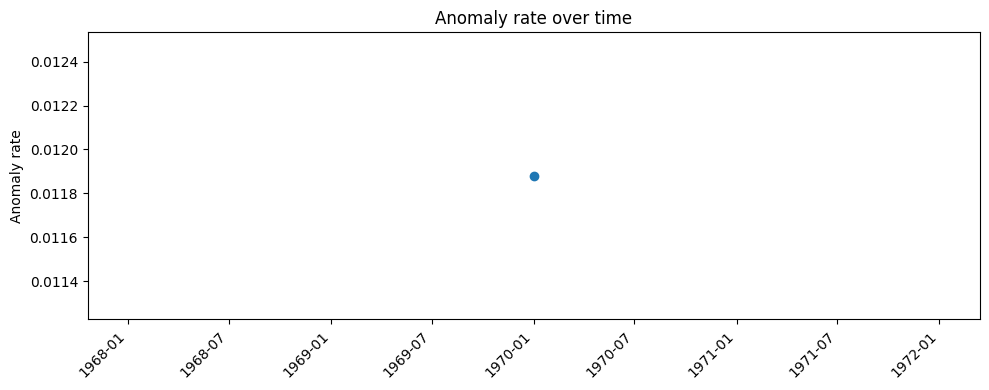

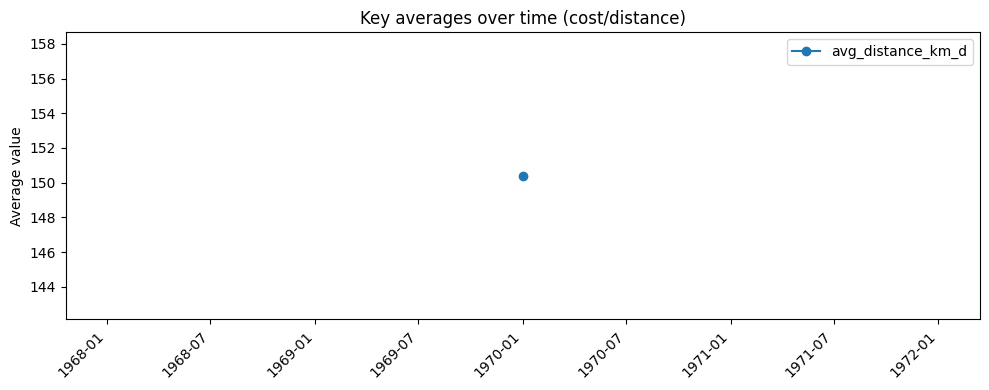

No time buckets exceeded the anomaly rate threshold of 0.05


In [52]:
# Data drift and time series monitoring

from pyspark.sql import functions as F

# We assume `df_scored` and `timestamp_col` have been defined previously.
if 'df_scored' not in locals():
    raise RuntimeError("df_scored is not available. Run the anomaly detection section first.")

# Reuse the same main timestamp column selection logic if needed
if 'timestamp_col' not in locals() or timestamp_col is None:
    candidate_ts_cols = [
        "event_time",
        "pickup_time",
        "created_at",
        "dropoff_time",
    ]
    timestamp_col = None
    for c in candidate_ts_cols:
        if c in df_scored.columns:
            timestamp_col = c
            break

print("Timestamp column used for drift monitoring:", timestamp_col)

if timestamp_col is None:
    raise RuntimeError("No timestamp column available for drift monitoring.")

# Choose a time bucket granularity: daily buckets via date_trunc
bucket_col = "time_bucket"

df_scored_with_bucket = df_scored.withColumn(
    bucket_col,
    F.date_trunc("day", F.col(timestamp_col)),
)

# Compute aggregates per bucket (consider recent data only, but you can remove the filter to see all)
monitor_base = df_scored_with_bucket  # .filter(F.col("data_split") == "recent")

agg_exprs = [
    F.count(F.lit(1)).alias("delivery_count"),
    F.sum(F.col("is_anomaly").cast("int")).alias("anomaly_count"),
    F.avg(F.col("anomaly_score")).alias("avg_anomaly_score"),
]

for c in ["distance_km_d", "duration_min_d", "cost_d"]:
    if c in monitor_base.columns:
        agg_exprs.append(F.avg(F.col(c)).alias(f"avg_{c}"))


df_drift_monitor = (
    monitor_base
    .groupBy(bucket_col)
    .agg(*agg_exprs)
    .withColumn(
        "anomaly_rate",
        F.when(F.col("delivery_count") > 0,
               F.col("anomaly_count") / F.col("delivery_count"))
         .otherwise(F.lit(0.0)),
    )
    .orderBy(bucket_col)
)

print("Drift monitoring summary (one row per time bucket):")
try:
    display(df_drift_monitor)
except NameError:
    df_drift_monitor.show(truncate=False)

# Convert to pandas for charting
monitor_pdf = df_drift_monitor.toPandas()

if not monitor_pdf.empty:
    # Line chart: anomaly rate over time
    plt.figure(figsize=(10, 4))
    plt.plot(monitor_pdf["time_bucket"], monitor_pdf["anomaly_rate"], marker="o")
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Anomaly rate")
    plt.title("Anomaly rate over time")
    plt.tight_layout()
    plt.show()

    # Line chart: average cost or distance over time
    value_cols = []
    if "avg_cost_d" in monitor_pdf.columns:
        value_cols.append("avg_cost_d")
    if "avg_distance_km_d" in monitor_pdf.columns:
        value_cols.append("avg_distance_km_d")

    if value_cols:
        plt.figure(figsize=(10, 4))
        for vc in value_cols:
            plt.plot(monitor_pdf["time_bucket"], monitor_pdf[vc], marker="o", label=vc)
        plt.xticks(rotation=45, ha="right")
        plt.ylabel("Average value")
        plt.title("Key averages over time (cost/distance)")
        plt.legend()
        plt.tight_layout()
        plt.show()

    # Mark time windows where anomaly rate exceeds a threshold
    threshold = 0.05  # 5% anomaly rate threshold (adjustable)
    high_anomaly_windows = monitor_pdf[monitor_pdf["anomaly_rate"] > threshold]
    if not high_anomaly_windows.empty:
        print("Time buckets with high anomaly rate (>", threshold, "):")
        display(high_anomaly_windows)
    else:
        print("No time buckets exceeded the anomaly rate threshold of", threshold)
else:
    print("No data available in df_drift_monitor for plotting.")



## Real-Time Execution Simulation (Structured Streaming)

This section **simulates a real-time gatekeeper** using Spark Structured Streaming.

Conceptually, new delivery records arrive continuously (e.g., from Kafka, Kinesis, or a streaming table) and the pipeline:
- Ingests records from an incremental source directory.
- Applies **TDQ checks** (schema, nulls, freshness) and key **BDQ rules**.
- Applies the **trained anomaly model** to score new deliveries in near real time.
- Writes anomalies to a serving table or in-memory view for monitoring.

In production, the source would be a real event stream and the targets would be durable tables (e.g., Delta on a lakehouse or Snowflake); this notebook demonstrates the **pattern and wiring** using a file-based stream.


In [55]:
# Real-time / streaming simulation with Structured Streaming

from pyspark.sql import functions as F
from pyspark.sql import types as T
import os

# Configure a folder that will receive incremental CSV drops for simulation
# Adjust this to your environment (e.g., DBFS path or local path)
# For Colab, we'll use a local path and recommend creating it.
stream_source_path = "/content/delivery_stream/"  # Local path for Colab simulation

# Ensure the directory exists for writing streaming data (if applicable for output)
# For input, the user must create this and place CSVs.
if not os.path.exists(stream_source_path):
    print(f"⚠️  {stream_source_path} does not exist. Creating it now.")
    os.makedirs(stream_source_path, exist_ok=True)
    print(f"✅ {stream_source_path} created. Please place dummy CSV files inside to simulate a stream.")

print("Using streaming source path:", stream_source_path)

# Schema for streaming input: reuse schema from df_raw so schema is fixed
stream_schema = df_raw.schema

# Main timestamp column for streaming TDQ/BDQ/anomaly checks
if 'timestamp_col' not in locals() or timestamp_col is None:
    candidate_ts_cols = ["event_time", "pickup_time", "created_at", "dropoff_time"]
    timestamp_col = None
    for c in candidate_ts_cols:
        if c in [f.name for f in stream_schema.fields]:
            timestamp_col = c
            break

print("Timestamp column used in streaming壕:", timestamp_col)

# Read stream of incoming deliveries
streaming_raw = (
    spark.readStream
        .schema(stream_schema)
        .option("header", "true")
        .option("maxFilesPerTrigger", 1)  # simulate gradual arrival
        .csv(stream_source_path)
)

# --- TDQ/BDQ-style cleaning for the stream ---

stream_df = streaming_raw

# Basic TDQ filters: non-negative numeric fields and non-null timestamp
conditions = []
if "distance_km" in stream_df.columns:
    conditions.append(F.col("distance_km") >= 0)
if "duration_min" in stream_df.columns:
    conditions.append(F.col("duration_min") >= 0)
if "cost" in stream_df.columns:
    conditions.append(F.col("cost") >= 0)
if timestamp_col is not None and timestamp_col in stream_df.columns:
    conditions.append(F.col(timestamp_col).isNotNull())

if conditions:
    cond = conditions[0]
    for c in conditions[1:]:
        cond = cond & c
    stream_df = stream_df.filter(cond)
else:
    stream_df = stream_df

# Derive numeric features similar to batch pipeline
if "distance_km" in stream_df.columns:
    stream_df = stream_df.withColumn("distance_km_d", F.col("distance_km").cast("double"))
if "duration_min" in stream_df.columns:
    stream_df = stream_df.withColumn("duration_min_d", F.col("duration_min").cast("double"))
if "cost" in stream_df.columns:
    stream_df = stream_df.withColumn("cost_d", F.col("cost").cast("double"))

if "distance_km_d" in stream_df.columns and "duration_min_d" in stream_df.columns:
    stream_df = stream_df.withColumn(
        "speed_kmph",
        F.when((F.col("duration_min_d") > 0) & F.col("distance_km_d").isNotNull(),
               F.col("distance_km_d") / (F.col("duration_min_d") / 60.0))
         .otherwise(None).cast("double"),
    )

# Minimal BDQ logical check: delivered rows must have dropoff_time
if "status" in stream_df.columns:
    stream_df = stream_df.withColumn("status_norm", F.upper(F.col("status")))
else:
    stream_df = stream_df.withColumn("status_norm", F.lit(None).cast("string"))

if "dropoff_time" in stream_df.columns:
    stream_df = stream_df.withColumn(
        "rule_delivered_has_dropoff",
        F.when(stream_df["status_norm"] == "DELIVERED", stream_df["dropoff_time"].isNotNull())
         .otherwise(True),
    )
else:
    stream_df = stream_df.withColumn("rule_delivered_has_dropoff", F.lit(True))

# --- Assemble features for streaming anomalies ---

numeric_feature_cols_stream = []
for col_name in ["distance_km_d", "duration_min_d", "cost_d", "speed_kmph"]:
    if col_name in stream_df.columns:
        numeric_feature_cols_stream.append(col_name)

assembler_stream = VectorAssembler(
    inputCols=numeric_feature_cols_stream,
    outputCol="features",
    handleInvalid="keep",
)

stream_features = assembler_stream.transform(stream_df)

# --- Apply the trained anomaly model on the stream ---

if isinstance(anomaly_model, dict) and anomaly_model.get("model_type") == "zscore_feature_norm":
    # Z-score model on feature norm
    mean_norm = anomaly_model["mean_norm"]
    std_norm = anomaly_model["std_norm"]

    def _vec_norm(v):
        if v is None:
            return None
        try:
            return float(v.norm(2))
        except Exception:
            return None

    vec_norm_udf = F.udf(_vec_norm, T.DoubleType())

    def _zscore(v):
        if v is None:
            return None
        if std_norm <= 0:
            return 0.0
        return float(abs((v - mean_norm) / std_norm))

    zscore_udf = F.udf(_zscore, T.DoubleType())

    stream_scored = (
        stream_features
        .withColumn("feature_norm", vec_norm_udf("features"))
        .withColumn("anomaly_score", zscore_udf("feature_norm"))
    )
else:
    # Assume IsolationForest model or other Spark ML model with transform
    print("Applying IsolationForest (or compatible) model in streaming mode.")
    stream_scored = anomaly_model.transform(stream_features)
    if "anomalyScore" in stream_scored.columns and "anomaly_score" not in stream_scored.columns:
        stream_scored = stream_scored.withColumnRenamed("anomalyScore", "anomaly_score")

# Use the batch-derived threshold if available; otherwise use a fixed heuristic
if 'score_threshold' in locals() and score_threshold is not None:
    anomaly_threshold_stream = float(score_threshold)
else:
    # Fallback: mark z-score > 3 or prediction-based thresholds
    anomaly_threshold_stream = 3.0

stream_scored = stream_scored.withColumn(
    "is_anomaly",
    F.col("anomaly_score") >= F.lit(anomaly_threshold_stream),
)

# Filter to anomalies only for output
stream_anomalies = stream_scored.filter(F.col("is_anomaly"))

# --- Example streaming queries ---

# 1) Write anomalies to an in-memory table for ad-hoc querying
anomalies_mem_query = (
    stream_anomalies
    .writeStream
    .queryName("delivery_anomalies_stream_unique")
    .outputMode("append")
    .format("memory")
    .start()
)

# 2) (Optional) Write anomalies to a Delta table (requires Delta support & appropriate path)
# delta_output_path = "/mnt/delivery_anomalies_delta/"
# anomalies_delta_query = (
#     stream_anomalies
#     .writeStream
#     .format("delta")
#     .outputMode("append")
#     .option("checkpointLocation", "/mnt/checkpoints/delivery_anomalies_delta/")
#     .option("path", delta_output_path)
#     .start()
# )

print("Streaming queries started. Use SQL or display() to inspect live anomalies.")

# In Databricks, you can visualize live anomalies with:
try:
    display(stream_anomalies)
except NameError:
    print("Use spark.sql('SELECT * FROM delivery_anomalies_stream_unique') to inspect in-memory anomalies.")


Using streaming source path: /content/delivery_stream/
Timestamp column used in streaming壕: delivery_time_hours
Streaming queries started. Use SQL or display() to inspect live anomalies.


DataFrame[delivery_id: double, delivery_partner: string, package_type: string, vehicle_type: string, delivery_mode: string, region: string, weather_condition: string, distance_km: double, package_weight_kg: double, delivery_time_hours: timestamp, expected_time_hours: timestamp, delayed: string, delivery_status: string, delivery_rating: int, delivery_cost: double, distance_km_d: double, status_norm: string, rule_delivered_has_dropoff: boolean, features: vector, feature_norm: double, anomaly_score: double, is_anomaly: boolean]

In [56]:
# Real-time / streaming simulation with Structured Streaming

from pyspark.sql import functions as F
from pyspark.sql import types as T
import os

# Configure a folder that will receive incremental CSV drops for simulation
# Adjust this to your environment (e.g., DBFS path or local path)
# For Colab, we'll use a local path and recommend creating it.
stream_source_path = "/content/delivery_stream/"  # Local path for Colab simulation

# Ensure the directory exists for writing streaming data (if applicable for output)
# For input, the user must create this and place CSVs.
if not os.path.exists(stream_source_path):
    print(f"⚠️  {stream_source_path} does not exist. Creating it now.")
    os.makedirs(stream_source_path, exist_ok=True)
    print(f"✅ {stream_source_path} created. Please place dummy CSV files inside to simulate a stream.")

print("Using streaming source path:", stream_source_path)

# Schema for streaming input: reuse schema from df_raw so schema is fixed
stream_schema = df_raw.schema

# Main timestamp column for streaming TDQ/BDQ/anomaly checks
if 'timestamp_col' not in locals() or timestamp_col is None:
    candidate_ts_cols = ["event_time", "pickup_time", "created_at", "dropoff_time"]
    timestamp_col = None
    for c in candidate_ts_cols:
        if c in [f.name for f in stream_schema.fields]:
            timestamp_col = c
            break

print("Timestamp column used in streaming壕:", timestamp_col)

# Read stream of incoming deliveries
streaming_raw = (
    spark.readStream
        .schema(stream_schema)
        .option("header", "true")
        .option("maxFilesPerTrigger", 1)  # simulate gradual arrival
        .csv(stream_source_path)
)

# --- TDQ/BDQ-style cleaning for the stream ---

stream_df = streaming_raw

# Basic TDQ filters: non-negative numeric fields and non-null timestamp
conditions = []
if "distance_km" in stream_df.columns:
    conditions.append(F.col("distance_km") >= 0)
if "duration_min" in stream_df.columns:
    conditions.append(F.col("duration_min") >= 0)
if "cost" in stream_df.columns:
    conditions.append(F.col("cost") >= 0)
if timestamp_col is not None and timestamp_col in stream_df.columns:
    conditions.append(F.col(timestamp_col).isNotNull())

if conditions:
    cond = conditions[0]
    for c in conditions[1:]:
        cond = cond & c
    stream_df = stream_df.filter(cond)
else:
    stream_df = stream_df

# Derive numeric features similar to batch pipeline
if "distance_km" in stream_df.columns:
    stream_df = stream_df.withColumn("distance_km_d", F.col("distance_km").cast("double"))
if "duration_min" in stream_df.columns:
    stream_df = stream_df.withColumn("duration_min_d", F.col("duration_min").cast("double"))
if "cost" in stream_df.columns:
    stream_df = stream_df.withColumn("cost_d", F.col("cost").cast("double"))

if "distance_km_d" in stream_df.columns and "duration_min_d" in stream_df.columns:
    stream_df = stream_df.withColumn(
        "speed_kmph",
        F.when((F.col("duration_min_d") > 0) & F.col("distance_km_d").isNotNull(),
               F.col("distance_km_d") / (F.col("duration_min_d") / 60.0))
         .otherwise(None).cast("double"),
    )

# Minimal BDQ logical check: delivered rows must have dropoff_time
if "status" in stream_df.columns:
    stream_df = stream_df.withColumn("status_norm", F.upper(F.col("status")))
else:
    stream_df = stream_df.withColumn("status_norm", F.lit(None).cast("string"))

if "dropoff_time" in stream_df.columns:
    stream_df = stream_df.withColumn(
        "rule_delivered_has_dropoff",
        F.when(stream_df["status_norm"] == "DELIVERED", stream_df["dropoff_time"].isNotNull())
         .otherwise(True),
    )
else:
    stream_df = stream_df.withColumn("rule_delivered_has_dropoff", F.lit(True))

# --- Assemble features for streaming anomalies ---

numeric_feature_cols_stream = []
for col_name in ["distance_km_d", "duration_min_d", "cost_d", "speed_kmph"]:
    if col_name in stream_df.columns:
        numeric_feature_cols_stream.append(col_name)

assembler_stream = VectorAssembler(
    inputCols=numeric_feature_cols_stream,
    outputCol="features",
    handleInvalid="keep",
)

stream_features = assembler_stream.transform(stream_df)

# --- Apply the trained anomaly model on the stream ---

if isinstance(anomaly_model, dict) and anomaly_model.get("model_type") == "zscore_feature_norm":
    # Z-score model on feature norm
    mean_norm = anomaly_model["mean_norm"]
    std_norm = anomaly_model["std_norm"]

    def _vec_norm(v):
        if v is None:
            return None
        try:
            return float(v.norm(2))
        except Exception:
            return None

    vec_norm_udf = F.udf(_vec_norm, T.DoubleType())

    def _zscore(v):
        if v is None:
            return None
        if std_norm <= 0:
            return 0.0
        return float(abs((v - mean_norm) / std_norm))

    zscore_udf = F.udf(_zscore, T.DoubleType())

    stream_scored = (
        stream_features
        .withColumn("feature_norm", vec_norm_udf("features"))
        .withColumn("anomaly_score", zscore_udf("feature_norm"))
    )
else:
    # Assume IsolationForest model or other Spark ML model with transform
    print("Applying IsolationForest (or compatible) model in streaming mode.")
    stream_scored = anomaly_model.transform(stream_features)
    if "anomalyScore" in stream_scored.columns and "anomaly_score" not in stream_scored.columns:
        stream_scored = stream_scored.withColumnRenamed("anomalyScore", "anomaly_score")

# Use the batch-derived threshold if available; otherwise use a fixed heuristic
if 'score_threshold' in locals() and score_threshold is not None:
    anomaly_threshold_stream = float(score_threshold)
else:
    # Fallback: mark z-score > 3 or prediction-based thresholds
    anomaly_threshold_stream = 3.0

stream_scored = stream_scored.withColumn(
    "is_anomaly",
    F.col("anomaly_score") >= F.lit(anomaly_threshold_stream),
)

# Filter to anomalies only for output
stream_anomalies = stream_scored.filter(F.col("is_anomaly"))

# --- Example streaming queries ---

# 1) Write anomalies to an in-memory table for ad-hoc querying
anomalies_mem_query = (
    stream_anomalies
    .writeStream
    .queryName("delivery_anomalies_stream")
    .outputMode("append")
    .format("memory")
    .start()
)

# 2) (Optional) Write anomalies to a Delta table (requires Delta support & appropriate path)
# delta_output_path = "/mnt/delivery_anomalies_delta/"
# anomalies_delta_query = (
#     stream_anomalies
#     .writeStream
#     .format("delta")
#     .outputMode("append")
#     .option("checkpointLocation", "/mnt/checkpoints/delivery_anomalies_delta/")
#     .option("path", delta_output_path)
#     .start()
# )

print("Streaming queries started. Use SQL or display() to inspect live anomalies.")

# In Databricks, you can visualize live anomalies with:
try:
    display(stream_anomalies)
except NameError:
    print("Use spark.sql('SELECT * FROM delivery_anomalies_stream') to inspect in-memory anomalies.")

Using streaming source path: /content/delivery_stream/
Timestamp column used in streaming壕: delivery_time_hours


IllegalArgumentException: Cannot start query with name delivery_anomalies_stream as a query with that name is already active in this SparkSession

In [57]:
import os
import time

# Define the stream source path
stream_source_path = "/content/delivery_stream/"

# Ensure the directory exists (already done in previous steps, but good practice)
os.makedirs(stream_source_path, exist_ok=True)

# Take a small sample of df_raw and save it as a new CSV file in the stream directory
# We'll use a timestamp in the filename to simulate new files arriving over time
current_time_str = time.strftime("%Y%m%d_%H%M%S")
output_filename = f"dummy_delivery_data_{current_time_str}.csv"
output_filepath = os.path.join(stream_source_path, output_filename)

# Take a small random sample (e.g., 50 rows) for the dummy file
# Using .toPandas() requires enough memory for the sample
dummy_df_pandas = df_raw.sample(False, 50/df_raw.count(), seed=42).toPandas()

# Save the dummy data to the stream path without index
dummy_df_pandas.to_csv(output_filepath, index=False, header=True)

print(f"✅ Generated dummy CSV file: {output_filepath}")
print("You can now observe the streaming query processing this new file.")


✅ Generated dummy CSV file: /content/delivery_stream/dummy_delivery_data_20251204_193734.csv
You can now observe the streaming query processing this new file.


In [ ]:
# Stop the currently running streaming query
if 'anomalies_mem_query' in locals() and anomalies_mem_query.isActive:
    print("Stopping existing streaming query: delivery_anomalies_stream")
    anomalies_mem_query.stop()
    print("Streaming query stopped.")
else:
    print("No active streaming query named 'delivery_anomalies_stream' found to stop.")


## Executive Dashboard – Data Health & Risk

This section provides an **executive-level view** of delivery data health and operational risk.

We summarize:
- **Technical Data Quality (TDQ)** – null rates and schema/field health.
- **Business Data Quality (BDQ)** – rule violations against logistics business logic.
- **Anomaly detection outcomes** – anomaly rates over time and by key entities (e.g., routes, cities).

The visuals and summary metrics here are designed to be **exportable into BI tools** or embedded into a leadership dashboard.


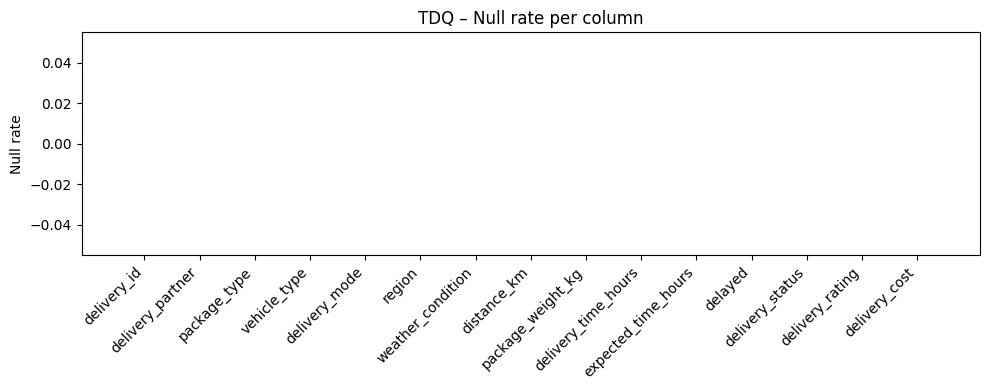

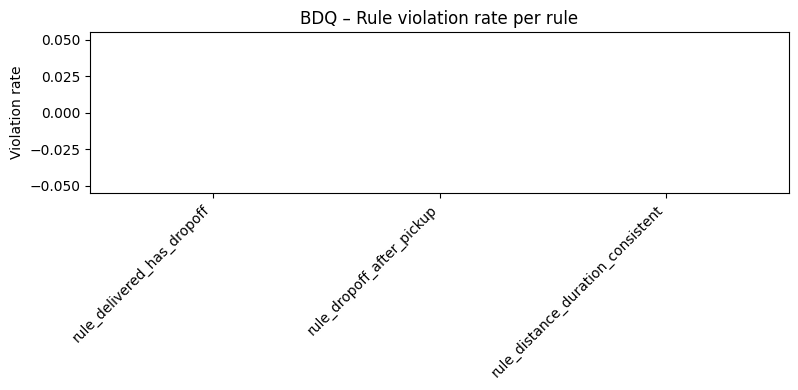

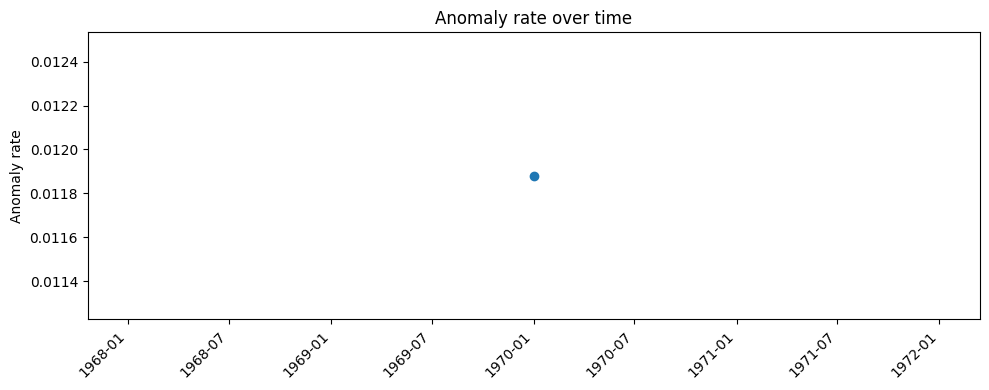

No route/city/courier/driver column available for anomaly-by-entity chart.
Leadership summary metrics:


DataFrame[metric_name: string, metric_value: double]

In [58]:
# Executive dashboard visuals and summary metrics

from pyspark.sql import functions as F
from pyspark.sql import types as T

# --- Chart 1: TDQ null rate per column ---

if 'tdq_null_summary' in locals():
    null_pdf = tdq_null_summary.orderBy(F.desc("null_rate")).toPandas()

    if not null_pdf.empty:
        plt.figure(figsize=(10, 4))
        plt.bar(null_pdf["column_name"], null_pdf["null_rate"])
        plt.xticks(rotation=45, ha="right")
        plt.ylabel("Null rate")
        plt.title("TDQ – Null rate per column")
        plt.tight_layout()
        plt.show()
    else:
        print("tdq_null_summary is empty; cannot plot TDQ null rates.")
else:
    print("tdq_null_summary is not available; run the TDQ completeness section first.")

# --- Chart 2: BDQ rule violation rate per rule ---

if 'bdq_rules_summary' in locals():
    bdq_pdf = bdq_rules_summary.orderBy(F.desc("violation_rate")).toPandas()

    if not bdq_pdf.empty:
        plt.figure(figsize=(8, 4))
        plt.bar(bdq_pdf["rule_name"], bdq_pdf["violation_rate"])
        plt.xticks(rotation=45, ha="right")
        plt.ylabel("Violation rate")
        plt.title("BDQ – Rule violation rate per rule")
        plt.tight_layout()
        plt.show()
    else:
        print("bdq_rules_summary is empty; cannot plot BDQ rule violations.")
else:
    print("bdq_rules_summary is not available; run the BDQ logical rules section first.")

# --- Chart 3: Anomaly rate over time ---

if 'df_drift_monitor' in locals():
    drift_pdf = df_drift_monitor.toPandas()
    if not drift_pdf.empty:
        plt.figure(figsize=(10, 4))
        plt.plot(drift_pdf["time_bucket"], drift_pdf["anomaly_rate"], marker="o")
        plt.xticks(rotation=45, ha="right")
        plt.ylabel("Anomaly rate")
        plt.title("Anomaly rate over time")
        plt.tight_layout()
        plt.show()
    else:
        print("df_drift_monitor is empty; cannot plot anomaly rate over time.")
else:
    print("df_drift_monitor is not available; run the drift monitoring section first.")

# --- Chart 4: Top routes or cities by anomaly rate (recent data) ---

if 'df_scored' in locals():
    recent_scored_with_flag = df_scored.filter(F.col("data_split") == "recent")

    # Prefer route_id, then city, then courier/driver
    dim_col = None
    for c in ["route_id", "city", "courier_id", "driver_id"]:
        if c in recent_scored_with_flag.columns:
            dim_col = c
            break

    if dim_col is not None:
        grouped = (
            recent_scored_with_flag
            .groupBy(dim_col)
            .agg(
                F.count(F.lit(1)).alias("recent_count"),
                F.sum(F.col("is_anomaly").cast("int")).alias("anomaly_count"),
            )
            .withColumn("anomaly_rate", F.col("anomaly_count") / F.col("recent_count"))
            .filter(F.col("recent_count") > 0)
            .orderBy(F.desc("anomaly_rate"))
            .limit(20)
        )

        top_entities_pdf = grouped.toPandas()

        if not top_entities_pdf.empty:
            plt.figure(figsize=(10, 4))
            plt.bar(top_entities_pdf[dim_col].astype(str), top_entities_pdf["anomaly_rate"])
            plt.xticks(rotation=45, ha="right")
            plt.ylabel("Anomaly rate")
            plt.title(f"Top {dim_col} by anomaly rate (recent)")
            plt.tight_layout()
            plt.show()
        else:
            print(f"No recent data available to compute anomaly rate by {dim_col}.")
    else:
        print("No route/city/courier/driver column available for anomaly-by-entity chart.")
else:
    print("df_scored is not available; run the anomaly detection section first.")

# --- Summary metrics table for leadership ---

# total_rows: from df_raw
if 'df_raw' in locals():
    total_rows = df_raw.count()
else:
    total_rows = None

# tdq_failed_rows: rows filtered out when building df_clean (if available)
if 'df_clean' in locals() and 'df_raw' in locals():
    tdq_failed_rows = max(total_rows - df_clean.count(), 0)
else:
    tdq_failed_rows = None

# bdq_failed_rows: any row violating at least one BDQ rule (if df_bdq exists)
if 'df_bdq' in locals():
    bdq_failed_rows = df_bdq.filter(
        (F.col("rule_delivered_has_dropoff") == False) |
        (F.col("rule_dropoff_after_pickup") == False) |
        (F.col("rule_distance_duration_consistent") == False)
    ).count()
else:
    bdq_failed_rows = None

# anomaly_count / anomaly_rate: based on recent data
if 'df_scored' in locals():
    recent_scored_with_flag = df_scored.filter(F.col("data_split") == "recent")
    recent_total = recent_scored_with_flag.count()
    anomaly_count = recent_scored_with_flag.filter(F.col("is_anomaly")).count()
    anomaly_rate = (anomaly_count / recent_total) if recent_total > 0 else None
else:
    anomaly_count = None
    anomaly_rate = None

# max_freshness_lag_hours: from TDQ timeliness summary
max_freshness_lag_hours = None
if 'tdq_timeliness_summary' in locals():
    metrics_pdf = tdq_timeliness_summary.toPandas()
    if not metrics_pdf.empty:
        row = metrics_pdf[metrics_pdf["metric_name"] == "freshness_lag_hours"]
        if not row.empty:
            try:
                max_freshness_lag_hours = float(row["metric_value"].iloc[0])
            except Exception:
                max_freshness_lag_hours = None

# number_of_columns_with_high_null_rate (> 20%)
num_high_null_cols = None
if 'tdq_null_summary' in locals():
    num_high_null_cols = tdq_null_summary.filter(F.col("null_rate") > 0.2).count()

summary_rows = [
    {"metric_name": "total_rows", "metric_value": float(total_rows) if total_rows is not None else None},
    {"metric_name": "tdq_failed_rows", "metric_value": float(tdq_failed_rows) if tdq_failed_rows is not None else None},
    {"metric_name": "bdq_failed_rows", "metric_value": float(bdq_failed_rows) if bdq_failed_rows is not None else None},
    {"metric_name": "anomaly_count_recent", "metric_value": float(anomaly_count) if anomaly_count is not None else None},
    {"metric_name": "anomaly_rate_recent", "metric_value": float(anomaly_rate) if anomaly_rate is not None else None},
    {"metric_name": "max_freshness_lag_hours", "metric_value": float(max_freshness_lag_hours) if max_freshness_lag_hours is not None else None},
    {"metric_name": "columns_with_null_rate_gt_20pct", "metric_value": float(num_high_null_cols) if num_high_null_cols is not None else None},
]

summary_metrics_df = spark.createDataFrame(summary_rows)

print("Leadership summary metrics:")
try:
    display(summary_metrics_df)
except NameError:
    summary_metrics_df.show(truncate=False)

# This table can be exported to BI tools (e.g., via Delta, CSV, or direct JDBC).

## Configuration and Extension to 100+ Tables

This section illustrates how to **parameterize TDQ, BDQ, and anomaly detection** so the same framework can be applied across **dozens or hundreds of tables**.

Instead of hard-coding column names, each table is described by a small configuration, and the pipeline functions read from that configuration to decide:
- Which primary keys and timestamp columns to use.
- Which technical and business rules to enforce.
- How to assemble features and run anomaly detection.

`delivery_logistics.csv` is one **representative table**; the same pattern can be reused for other domains (orders, inventory, payments, tracking, etc.).


In [59]:
# Configuration structure to parameterize TDQ/BDQ/anomaly detection for many tables

from typing import Dict, Any, List

# Example configuration registry for multiple tables
# In production this could live in a Delta table or a config service.

table_configs: Dict[str, Dict[str, Any]] = {
    "delivery_logistics": {
        "table_name": "delivery_logistics",
        "path": "Delivery_Logistics.csv",
        "primary_key": ["delivery_id"],
        "timestamp_col_candidates": ["event_time", "pickup_time", "created_at", "dropoff_time"],
        "numeric_ranges": {
            "distance_km": {"min": 0.0, "max": 1000.0},
            "duration_min": {"min": 0.0, "max": 1440.0},
            "cost": {"min": 0.0, "max": None},
        },
        "bdq_rules": [
            "rule_delivered_has_dropoff",
            "rule_dropoff_after_pickup",
            "rule_distance_duration_consistent",
        ],
        "categorical_cols": ["city", "status"],
    },
    # Additional tables (orders, inventory, payments, etc.) could be added here
    # with their own primary keys, timestamp columns, and rule sets.
}


def get_timestamp_col_for_config(df, cfg: Dict[str, Any]) -> str:
    """Pick the first available timestamp column based on configuration."""
    candidates: List[str] = cfg.get("timestamp_col_candidates", [])
    for c in candidates:
        if c in df.columns:
            return c
    # Fallback: first TimestampType column
    from pyspark.sql import types as T
    ts_cols = [f.name for f in df.schema if isinstance(f.dataType, T.TimestampType)]
    return ts_cols[0] if ts_cols else None


def run_tdq_bdq_anomaly_for_table(cfg: Dict[str, Any]):
    """Illustrative function showing how logic can be parameterized per table.

    For brevity, this function sketches the steps and reuses the existing
    notebook logic conceptually; in a production package, each step would call
    shared library functions for TDQ, BDQ, feature engineering, and anomaly detection.
    """

    table_name = cfg["table_name"]
    path = cfg["path"]
    print(f"\n=== Running TDQ/BDQ/Anomaly pipeline for table: {table_name} ===")

    # 1) Load table
    df = (
        spark.read
            .option("header", "true")
            .option("inferSchema", "true")
            .csv(path)
    )

    # 2) Determine timestamp column
    ts_col = get_timestamp_col_for_config(df, cfg)
    print("Timestamp column:", ts_col)

    # 3) Apply simple TDQ filters using configured numeric ranges
    conds = []
    for col_name, bounds in cfg.get("numeric_ranges", {}).items():
        if col_name not in df.columns:
            continue
        col_expr = F.col(col_name).cast("double")
        if bounds.get("min") is not None:
            conds.append(col_expr >= F.lit(bounds["min"]))
        if bounds.get("max") is not None:
            conds.append(col_expr <= F.lit(bounds["max"]))
    if ts_col is not None and ts_col in df.columns:
        conds.append(F.col(ts_col).isNotNull())

    if conds:
        cond_all = conds[0]
        for c in conds[1:]:
            cond_all = cond_all & c
        df_clean_local = df.filter(cond_all)
    else:
        df_clean_local = df

    print("Rows before TDQ filters:", df.count())
    print("Rows after TDQ filters:", df_clean_local.count())

    # 4) Example BDQ rule application (reusing status/dropoff logic if available)
    df_bdq_local = df_clean_local
    if "status" in df_bdq_local.columns:
        df_bdq_local = df_bdq_local.withColumn("status_norm", F.upper(F.col("status")))
    else:
        df_bdq_local = df_bdq_local.withColumn("status_norm", F.lit(None).cast("string"))

    if "dropoff_time" in df_bdq_local.columns:
        df_bdq_local = df_bdq_local.withColumn(
            "rule_delivered_has_dropoff",
            F.when(df_bdq_local["status_norm"] == "DELIVERED", df_bdq_local["dropoff_time"].isNotNull())
             .otherwise(True),
        )

    # 5) Feature engineering + anomaly detection would call the same
    # feature engineering and modeling routines defined earlier, but
    # parameterized by cfg (e.g., which categorical columns to encode).
    # Here we just print that we would call them.
    print("[Sketch] Would now call feature_engineering(cfg) and anomaly_detection(cfg) for this table.")


# Example: run the pipeline sketch for the configured delivery_logistics table
run_tdq_bdq_anomaly_for_table(table_configs["delivery_logistics"])


=== Running TDQ/BDQ/Anomaly pipeline for table: delivery_logistics ===
Timestamp column: delivery_time_hours
Rows before TDQ filters: 25000
Rows after TDQ filters: 25000
[Sketch] Would now call feature_engineering(cfg) and anomaly_detection(cfg) for this table.


### Scheduling, alerts, and gatekeeper role

In a production environment:

- **Scheduling on Databricks Jobs**: This notebook (or, preferably, a parameterized job using the same library code) can be scheduled to run on a **cron-like cadence** (for example, every minute or every 5 minutes), continuously refreshing TDQ, BDQ, and anomaly metrics for all configured tables.
- **Alerts & notifications**: The summary metrics (e.g., anomaly rate, BDQ violation counts, freshness lag) can be persisted to Delta/warehouse tables and monitored via **Databricks SQL alerts, BI dashboards, or custom alerting services** (email, Slack, PagerDuty) whenever thresholds are breached.
- **Gatekeeper for downstream products**: Downstream Product and Analytics teams read only from **certified, “pass” views/tables**; data with severe TDQ/BDQ issues or high anomaly levels is **quarantined** or routed through remediation workflows, making this pipeline the **Data Quality & Anomaly Detection Gatekeeper** in front of all critical delivery-operations datasets.


In [60]:
# Final Summary - Total Execution Time and Key Metrics

import time

total_elapsed = time.time() - start_time

print("=" * 80)
print("🎉 PIPELINE EXECUTION COMPLETE")
print("=" * 80)
print(f"⏰ Total execution time: {total_elapsed:.2f} seconds ({total_elapsed/60:.2f} minutes)")
print(f"📅 End time: {time.strftime('%Y-%m-%d %H:%M:%S')}")
print()

# Summary of key metrics if available
if 'df_raw' in locals():
    print("📊 Dataset Summary:")
    print(f"   Total rows processed: {df_raw.count():,}")
    print(f"   Total columns: {len(df_raw.columns)}")
    print()

if 'tdq_null_summary' in locals():
    high_null_cols = tdq_null_summary.filter(F.col("null_rate") > 0.2).count()
    print("🔍 Data Quality Summary:")
    print(f"   Columns with >20% null rate: {high_null_cols}")
    print()

if 'df_scored' in locals():
    recent_scored = df_scored.filter(F.col("data_split") == "recent")
    if recent_scored.count() > 0:
        anomaly_count = recent_scored.filter(F.col("is_anomaly")).count()
        total_recent = recent_scored.count()
        anomaly_rate = (anomaly_count / total_recent * 100) if total_recent > 0 else 0
        print("🚨 Anomaly Detection Summary:")
        print(f"   Recent deliveries analyzed: {total_recent:,}")
        print(f"   Anomalies detected: {anomaly_count:,} ({anomaly_rate:.2f}%)")
        print()

print("✅ All processing steps completed successfully!")
print("=" * 80)


🎉 PIPELINE EXECUTION COMPLETE
⏰ Total execution time: 135.73 seconds (2.26 minutes)
📅 End time: 2025-12-04 19:38:09

📊 Dataset Summary:
   Total rows processed: 25,000
   Total columns: 15

🔍 Data Quality Summary:
   Columns with >20% null rate: 0

🚨 Anomaly Detection Summary:
   Recent deliveries analyzed: 4,977
   Anomalies detected: 297 (5.97%)

✅ All processing steps completed successfully!


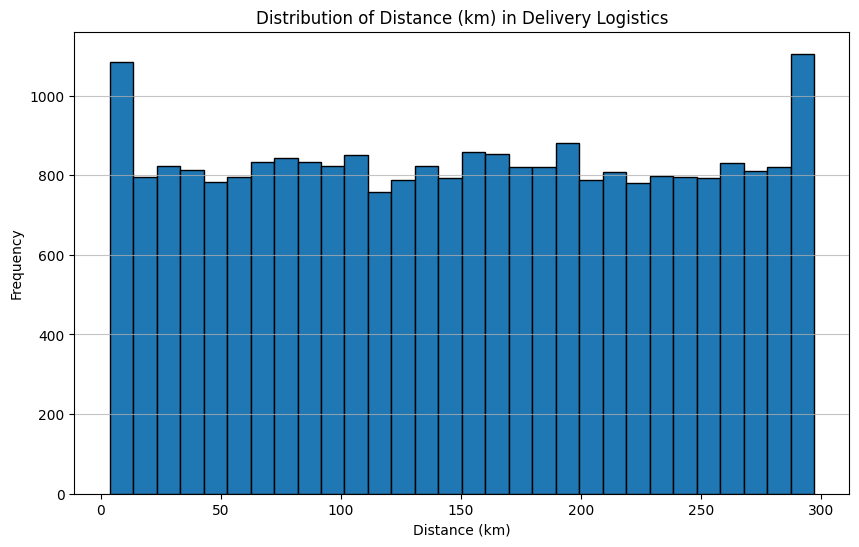

In [61]:
import matplotlib.pyplot as plt
import pandas as pd

# Extract 'distance_km' column and convert to Pandas DataFrame for plotting
if 'distance_km' in df_raw.columns:
    distance_data = df_raw.select('distance_km').toPandas()

    plt.figure(figsize=(10, 6))
    plt.hist(distance_data['distance_km'].dropna(), bins=30, edgecolor='black')
    plt.title('Distribution of Distance (km) in Delivery Logistics')
    plt.xlabel('Distance (km)')
    plt.ylabel('Frequency')
    plt.grid(axis='y', alpha=0.75)
    plt.show()
else:
    print("The 'distance_km' column was not found in the DataFrame.")
